# Weekly sales forecasting

Can recent weekly retailer proceeds from the observed households help plan the next four weeks? This forecast describes this dataset, not the retailer's full sales or the causal effect of CRM. `SALES_VALUE` is retailer proceeds after recorded adjustments, not profit or household out-of-pocket spending.

In [1]:
from pathlib import Path
import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/raw/transaction_data.csv").exists())
source = ROOT / "data/raw/transaction_data.csv"

## 1. Build and inspect the weekly series

Source weeks are relative identifiers, not calendar weeks. We require seven consecutive observed days per week and no missing week identifiers; the two partial boundary weeks are excluded. A day with no transactions would fail the check rather than silently become zero.

In [2]:
with duckdb.connect() as con:
    weekly = con.execute("""
        SELECT WEEK_NO AS week, min(DAY) AS first_day, max(DAY) AS last_day,
               count(DISTINCT DAY) AS observed_days,
               sum(SALES_VALUE) AS sales
        FROM read_csv_auto(?)
        GROUP BY WEEK_NO ORDER BY WEEK_NO
    """, [str(source)]).df()

assert weekly["week"].is_unique and weekly["sales"].notna().all()
assert weekly["week"].diff().dropna().eq(1).all()
assert weekly["first_day"].iloc[1:].reset_index(drop=True).equals(
    (weekly["last_day"].iloc[:-1] + 1).reset_index(drop=True)
)
print(weekly.head(3).to_string(index=False))
print(weekly.tail(3).to_string(index=False))

 week  first_day  last_day  observed_days    sales
    1          1         5              5  5211.16
    2          6        12              7 10821.35
    3         13        19              7 13498.20
 week  first_day  last_day  observed_days    sales
  100        692       698              7 93063.10
  101        699       705              7 84407.25
  102        706       711              6 71968.63


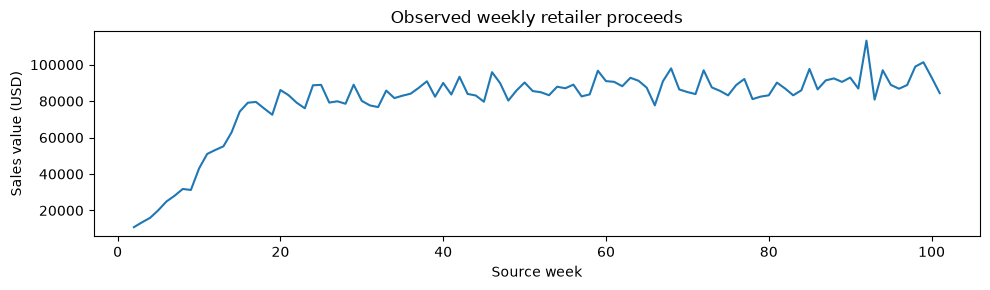

In [3]:
full = weekly.loc[weekly.observed_days.eq(7)].copy()
assert full["week"].diff().dropna().eq(1).all()
assert (full.last_day - full.first_day).eq(6).all()
series = full.set_index("week")["sales"].astype(float)
ax = series.plot(figsize=(10, 3), title="Observed weekly retailer proceeds")
ax.set(xlabel="Source week", ylabel="Sales value (USD)")
plt.tight_layout()
plt.show()

The early increase may reflect changing observation coverage or behaviour; its cause is unknown. We retain all complete weeks for the primary analysis and compare a recent-history window as a sensitivity check. Roughly two years of data and no verified calendar do not support a reliable annual seasonal model or holiday interpretation.

## 2. Four-week forecasts and rolling evaluation

Compare last week, the mean of the last four weeks, and simple exponential smoothing (SES). SES learns its smoothing weight using only each training window. We select the model by pooled validation MAE across four non-overlapping 4-week origins, then evaluate it on five later origins. At each origin the model sees only earlier weeks; later origins may use previously observed test weeks. This estimates repeated four-week forecasting, not one 20-week forecast. WAPE is the sum of absolute errors divided by the sum of actual sales.

In [4]:
HORIZON = 4
VALIDATION_ORIGINS = [62, 66, 70, 74]  # last observed source week
TEST_ORIGINS = [78, 82, 86, 90, 94]
MODELS = ["Last week", "4-week mean", "Exponential smoothing"]

def ses_fitted(values, alpha):
    level = values[0]
    errors = []
    for value in values[1:]:
        errors.append(value - level)
        level = alpha * value + (1 - alpha) * level
    return level, np.asarray(errors)

In [5]:
def forecast(train, model, horizon=HORIZON):
    values = np.asarray(train, dtype=float)
    if model == "Last week":
        prediction = values[-1]
    elif model == "4-week mean":
        prediction = values[-4:].mean()
    elif model == "Exponential smoothing":
        objective = lambda a: np.mean(ses_fitted(values, a[0])[1] ** 2)
        result = minimize(objective, x0=[0.5], bounds=[(0.001, 0.999)])
        if not result.success:
            raise RuntimeError(result.message)
        prediction = ses_fitted(values, result.x[0])[0]
    else:
        raise ValueError(model)
    return np.repeat(prediction, horizon)

In [6]:
def backtest(origins, history=None):
    rows = []
    for origin in origins:
        train = series.loc[:origin]
        if history is not None:
            train = train.tail(history)
        actual = series.loc[origin + 1:origin + HORIZON]
        assert len(actual) == HORIZON and train.index.max() == origin
        for model in MODELS:
            predicted = forecast(train, model)
            for step, (week, value) in enumerate(actual.items()):
                rows.append((origin, week, model, value, predicted[step]))
    return pd.DataFrame(rows, columns=["origin", "week", "model",
                                       "actual", "prediction"])

def score(frame):
    error = (frame.actual - frame.prediction).abs()
    return pd.Series({"MAE (USD)": error.mean(),
                      "WAPE (%)": 100 * error.sum() / frame.actual.abs().sum()})

In [7]:
validation = backtest(VALIDATION_ORIGINS)
validation_scores = validation.groupby("model").apply(
    score, include_groups=False).sort_values("MAE (USD)")
selected = validation_scores.index[0]
print("Validation; model selected by MAE:")
print(validation_scores.round(2).to_string())
print("Selected:", selected)

Validation; model selected by MAE:
                       MAE (USD)  WAPE (%)
model                                     
4-week mean              4630.04      5.26
Exponential smoothing    5791.30      6.58
Last week                6341.91      7.20
Selected: 4-week mean


In [8]:
test = backtest(TEST_ORIGINS)
test_scores = test.groupby("model").apply(score, include_groups=False)
print("Later rolling test (all models shown for transparency):")
print(test_scores.round(2).to_string())
print("Selected model test:")
print(test_scores.loc[selected].round(2).to_string())

Later rolling test (all models shown for transparency):
                       MAE (USD)  WAPE (%)
model                                     
4-week mean              5337.27      5.91
Exponential smoothing    5274.56      5.85
Last week                6332.70      7.02
Selected model test:
MAE (USD)    5337.27
WAPE (%)        5.91


## 3. Sensitivity and final forecast

The recent-history analysis repeats selection and evaluation using only the latest 32 weeks at each origin. It is a sensitivity check, not a second attempt to select the primary model using the test results. The final forecast uses the primary model and all complete observed weeks. An empirical error band uses the maximum absolute 4-week error at each validation origin; four origins are far too few to claim calibrated 95% coverage.

In [9]:
recent_val = backtest(VALIDATION_ORIGINS, history=32)
recent_selected = recent_val.groupby("model").apply(
    score, include_groups=False)["MAE (USD)"].idxmin()
recent_test = backtest(TEST_ORIGINS, history=32)
print("Recent-history selected:", recent_selected)
print(score(recent_test[recent_test.model == recent_selected]).round(2))

selected_val = validation[validation.model == selected].copy()
selected_val["error"] = (selected_val.actual - selected_val.prediction).abs()
band = selected_val.groupby("origin").error.max().max()
future_weeks = np.arange(series.index.max() + 1, series.index.max() + 5)
pred = forecast(series, selected)
future = pd.DataFrame({"week": future_weeks, "forecast": pred,
                       "lower": np.maximum(0, pred - band),
                       "upper": pred + band})
print("Illustrative error band (+/- USD):", round(band, 2))
print(future.round(2).to_string(index=False))

Recent-history selected: Exponential smoothing
MAE (USD)    5464.66
WAPE (%)        6.06
dtype: float64
Illustrative error band (+/- USD): 13926.33
 week  forecast    lower     upper
  102  94445.97 80519.64 108372.31
  103  94445.97 80519.64 108372.31
  104  94445.97 80519.64 108372.31
  105  94445.97 80519.64 108372.31


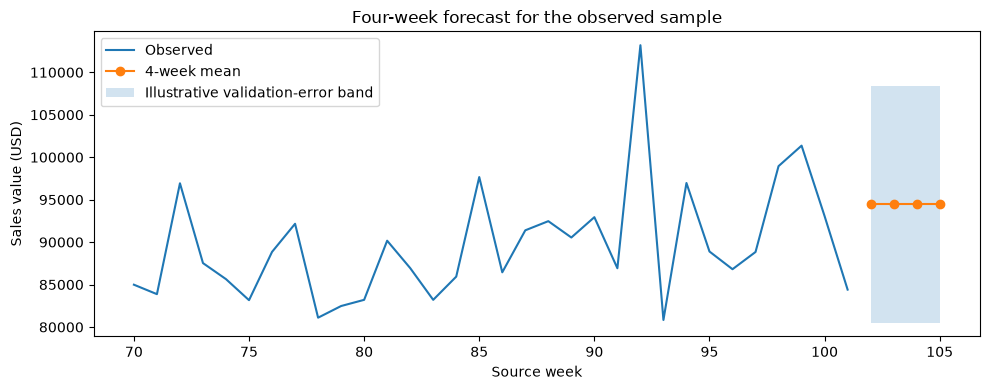

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
series.tail(32).plot(ax=ax, label="Observed")
ax.plot(future.week, future.forecast, marker="o", label=selected)
ax.fill_between(future.week, future.lower, future.upper, alpha=0.2,
                label="Illustrative validation-error band")
ax.set(xlabel="Source week", ylabel="Sales value (USD)",
       title="Four-week forecast for the observed sample")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/07_weekly_sales_forecast.png", dpi=140)
plt.show()

## Interpretation

Review validation and test errors before using the forecast for planning. The forecast assumes recent patterns persist and covers only recorded households. It excludes the partial final week, uses no future information, and does not measure incremental campaign revenue. The empirical band is descriptive, not a prediction interval with verified coverage. Assess the early sample ramp, data coverage and changing purchasing patterns before extending this into an operational forecast.